In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:

# Load MNIST handwritten digits dataset
(X_train, y_train), (X_test, y_test) = \
    tf.keras.datasets.mnist.load_data()

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)


Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


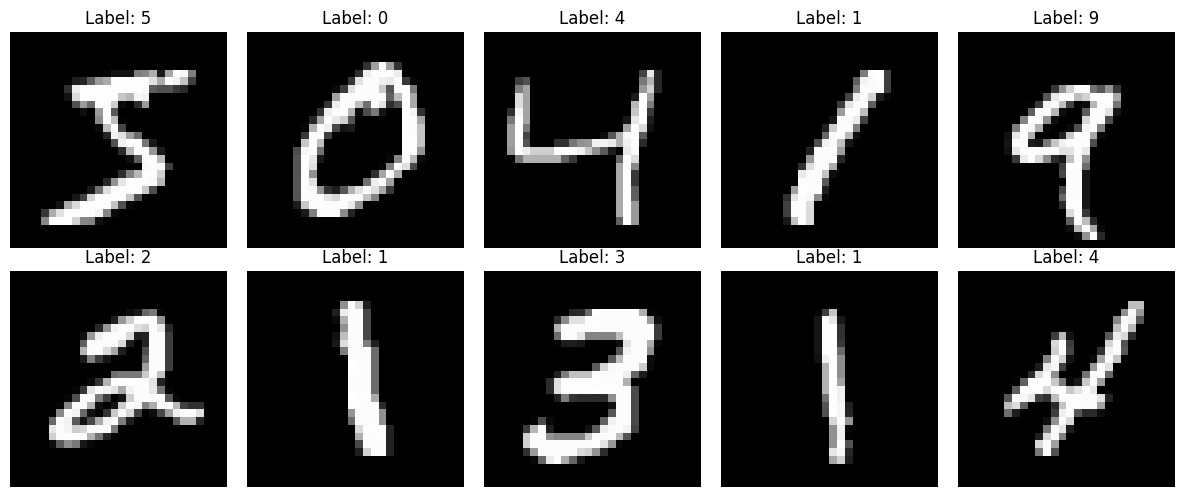

In [3]:

# Display first 10 handwritten digits
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [4]:

print("Image Shape:", X_train[0].shape)
print("Pixel Value Range:",
      X_train.min(), "to", X_train.max())

print("First Image Label:", y_train[0])


Image Shape: (28, 28)
Pixel Value Range: 0 to 255
First Image Label: 5


In [5]:

# Normalize pixel values to range 0-1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())


Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [6]:

# Add channel dimension for grayscale images
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (60000, 28, 28, 1)
Testing Data Shape: (10000, 28, 28, 1)


In [7]:

# Build CNN model
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dense(10, activation='softmax')
])

# Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:

# Compile CNN model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model compiled successfully!")


CNN Model compiled successfully!


In [9]:

# Train CNN model
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

print("Model training completed!")


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 32s 35ms/step - accuracy: 0.9476 - loss: 0.1717 - val_accuracy: 0.9813 - val_loss: 0.0628
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 39s 32ms/step - accuracy: 0.9835 - loss: 0.0524 - val_accuracy: 0.9888 - val_loss: 0.0413
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 33ms/step - accuracy: 0.9894 - loss: 0.0342 - val_accuracy: 0.9872 - val_loss: 0.0456
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 28s 33ms/step - accuracy: 0.9916 - loss: 0.0261 - val_accuracy: 0.9922 - val_loss: 0.0286
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 27s 32ms/step - accuracy: 0.9940 - loss: 0.0189 - val_accuracy: 0.9887 - val_loss: 0.0420
Model training completed!


In [10]:

# Evaluate CNN on test dataset
test_loss, test_accuracy = model.evaluate(
    X_test, y_test
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9890 - loss: 0.0309
Test Accuracy: 98.90%
Test Loss: 0.0309


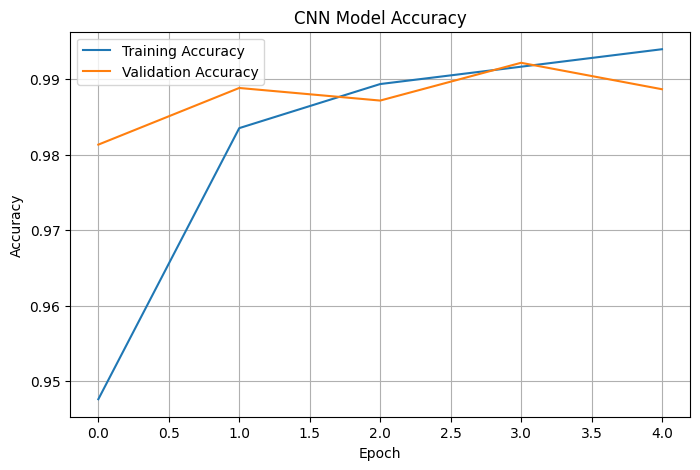

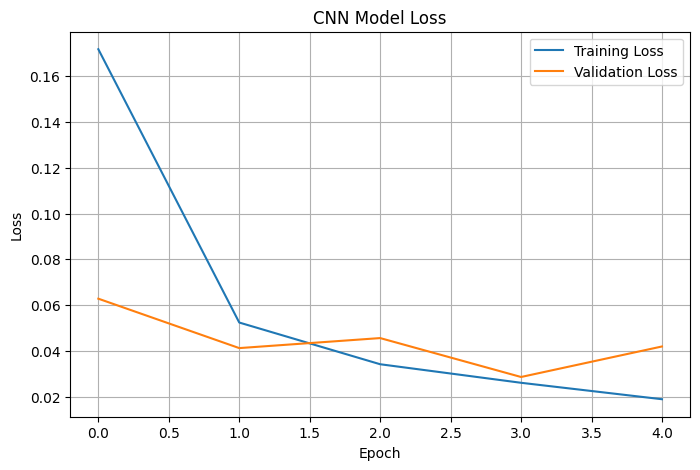

In [11]:

import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


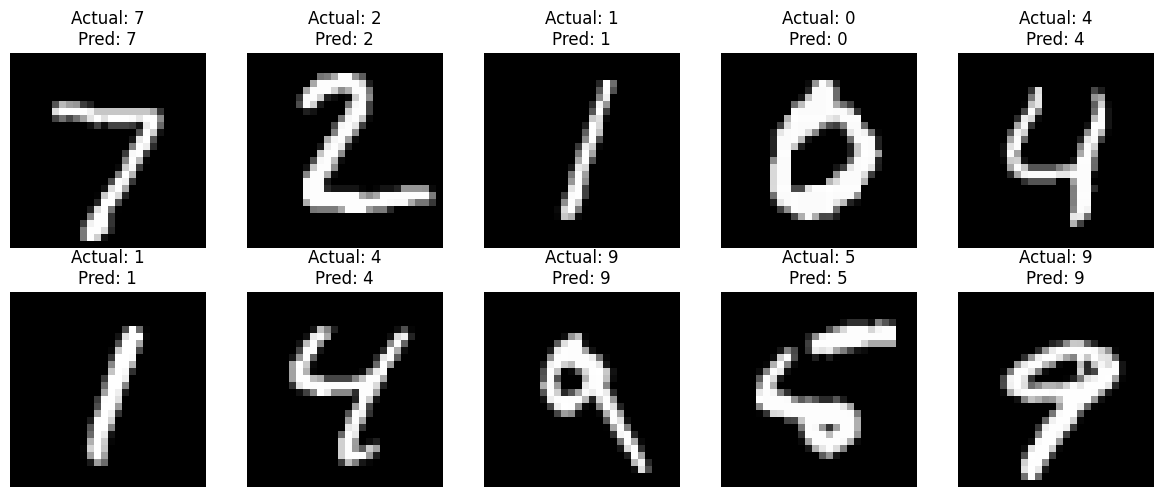

In [12]:

# Predict digits from test images
predictions = model.predict(X_test)

# Display 10 predictions
plt.figure(figsize=(12, 5))

for i in range(10):
    predicted_digit = np.argmax(predictions[i])
    actual_digit = y_test[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Actual: {actual_digit}\nPred: {predicted_digit}")
    plt.axis('off')

plt.tight_layout()
plt.show()


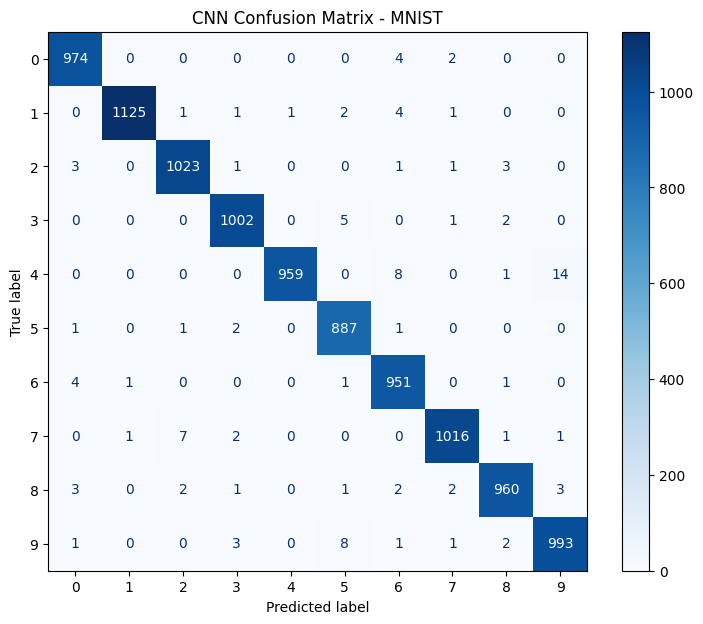

In [13]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Get predicted classes
y_pred = np.argmax(predictions, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(cmap='Blues', ax=ax)

plt.title("CNN Confusion Matrix - MNIST")
plt.show()


Total Incorrect Predictions: 110


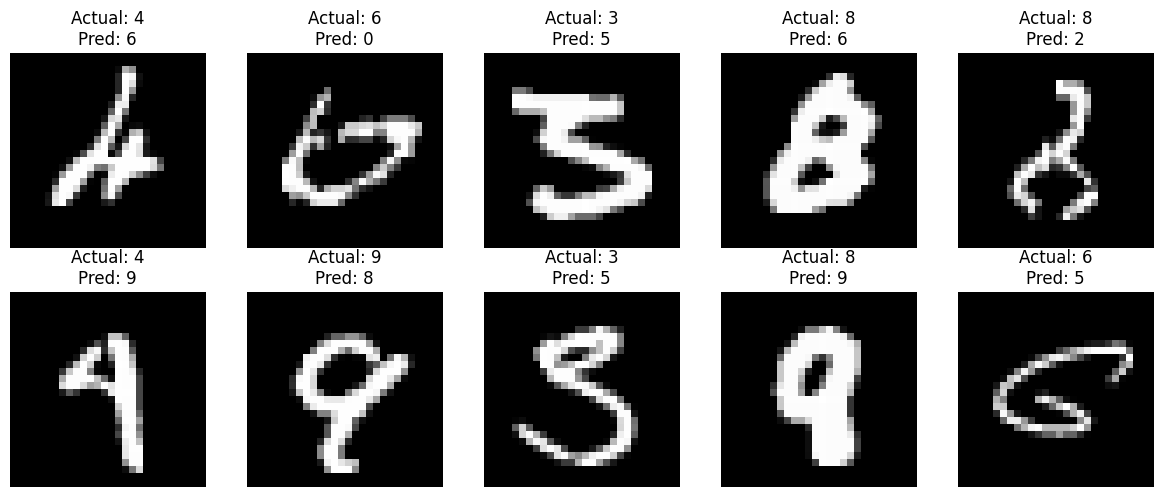

In [14]:

# Find incorrectly predicted images
wrong_indices = np.where(y_pred != y_test)[0]

print("Total Incorrect Predictions:", len(wrong_indices))

# Display first 10 incorrect predictions
plt.figure(figsize=(12, 5))

for i, idx in enumerate(wrong_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    plt.title(
        f"Actual: {y_test[idx]}\nPred: {y_pred[idx]}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()


In [15]:

# Save CNN model
model.save("handwritten_digit_cnn.keras")

print("CNN Model saved successfully!")


CNN Model saved successfully!
